# Buổi A3: Nhìn dữ liệu bằng biểu đồ, trước khi nhờ máy

**Hiện trường.** Trưởng khoa tuyên bố chắc nịch trong buổi giao ban: *"Bệnh nhân càng lớn tuổi thì càng tiến triển nặng. Cứ chọn 20 người cao tuổi nhất vào diện theo dõi sát."* Chị Hạnh có 20 suất và 442 bệnh án, nhưng chị chưa yên tâm: lỡ đúng thì tốt, lỡ sai thì 20 suất quý rơi nhầm chỗ.

Chị chưa cần máy. Chị cần **nhìn** cuốn sổ. Một biểu đồ tốt trả lời được những câu mà bảng số hàng trăm dòng không trả lời nổi.

**Mindset của người làm dữ liệu:** biểu đồ là công cụ *thẩm vấn*, không phải công cụ trang trí. Mỗi biểu đồ đặt ra một câu hỏi, và ta phải biết biểu đồ nào có thể *nói dối*.

**Chuẩn bị:** không cần tải file. Cú pháp đã học ở A1 và A2 (nạp dữ liệu, `scatter`, `plot`, `subplots`, `barh`, `imshow`...) sẽ không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Một cột trông ra sao? Trung bình có che giấu điều gì? |
| Chặng 1 | Chân dung của tất cả các cột cùng lúc |
| Chặng 2 | Kiểm chứng lời trưởng khoa: tuổi có thật sự dự báo bệnh? |
| Chặng 3 | Bản đồ tương quan: ai "đi cùng" ai? |
| Chặng 4 | Biểu đồ cũng có thể nói dối |

## Chặng 0: Một cột trông ra sao?

**Câu hỏi:** điểm tiến triển bệnh của 442 người phân bố thế nào, và con số trung bình có đủ để mô tả không?

Trung bình chỉ là *một con số đại diện*. Để thấy cả đám đông, ta dùng **biểu đồ cột tần suất** (histogram): chia trục ngang thành nhiều khoảng, đếm xem mỗi khoảng có bao nhiêu người.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

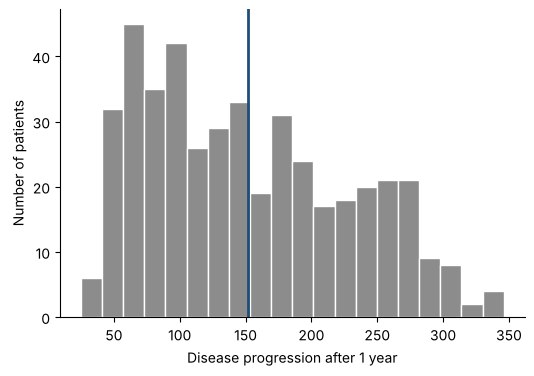

In [2]:
from sklearn.datasets import load_diabetes
original = load_diabetes(as_frame=True, scaled=False).frame
plt.hist(original["target"], bins=20, color=GRAY, edgecolor="white")
plt.axvline(original["target"].mean(), color=BLUE, linewidth=2)
plt.xlabel("Disease progression after 1 year")
plt.ylabel("Number of patients")
plt.show()

**Giải thích từng dòng**

- `original = load_diabetes(as_frame=True, scaled=False).frame`: (đã học ở A2) nạp bản sổ gốc.
- `plt.hist(original["target"], bins=20, color=GRAY, edgecolor="white")`: `plt.hist` vẽ **biểu đồ cột tần suất**. `bins=20` chia trục ngang thành 20 khoảng bằng nhau (càng nhiều khoảng thì càng chi tiết nhưng càng lởm chởm). `edgecolor="white"` viền trắng giữa các cột cho dễ phân biệt.
- `plt.axvline(original["target"].mean(), color=BLUE, linewidth=2)`: (đã học ở A1) kẻ đường dọc xanh tại điểm trung bình.
- `plt.xlabel(...); plt.ylabel(...); plt.show()`: ghi tên trục và hiện hình.

**Cách đọc**

- **Con số:** điểm trung bình khoảng 152, nhưng trung vị (số chính giữa) chỉ khoảng 140.
- **Bức tranh:** đám đông không đối xứng. Phần lớn bệnh nhân tập trung ở mức thấp đến vừa (50 đến 200), còn phía phải kéo một cái *đuôi dài* những ca nặng. Vài ca rất nặng kéo trung bình lên cao hơn trung vị. Nếu chỉ báo "trung bình 152", ta sẽ tưởng một bệnh nhân điển hình là 152, trong khi người ở chính giữa là 140.
- **Câu hỏi tiếp:** với một cột, histogram cho thấy hình dạng. Vậy với cả 10 cột cùng lúc thì sao?

**Mang về chặng 0:** trung bình không kể hết câu chuyện. Histogram cho thấy hình dạng của đám đông: đối xứng hay lệch, tập trung hay dàn trải.

## Chặng 1: Chân dung của tất cả các cột cùng lúc

**Câu hỏi:** trước khi so sánh các cột với nhau, mỗi cột riêng lẻ trông thế nào? Có cột nào bất thường?

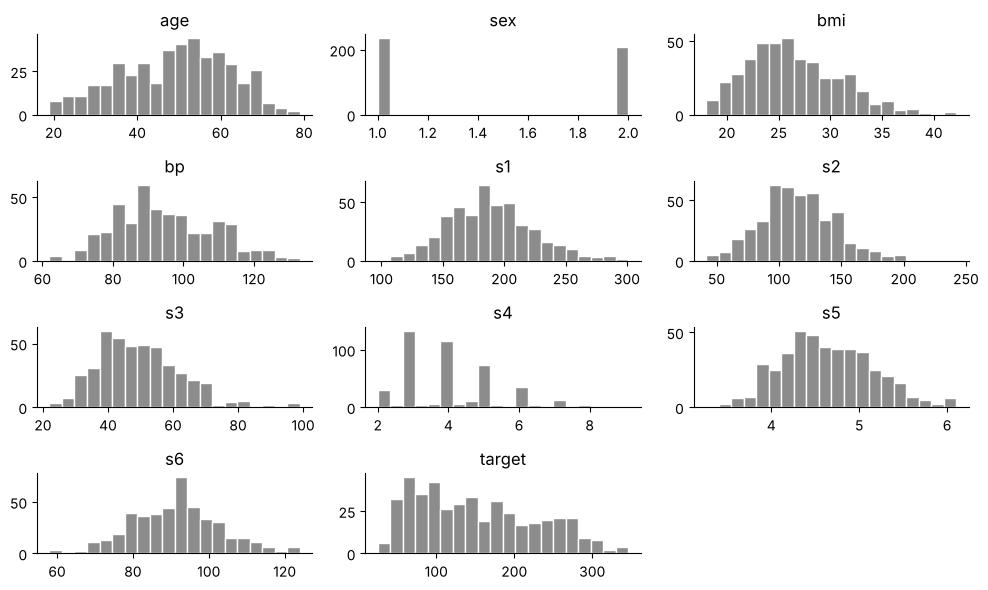

In [3]:
original.hist(bins=20, figsize=(10, 6), color=GRAY, edgecolor="white", grid=False)
plt.tight_layout()
plt.show()

**Giải thích từng dòng**

- `original.hist(bins=20, figsize=(10, 6), color=GRAY, edgecolor="white", grid=False)`: pandas có sẵn lệnh `hist()` gọi **trực tiếp trên bảng**: nó vẽ một histogram cho **mỗi cột số**, xếp thành lưới. `figsize=(10, 6)` đặt cỡ hình lớn hơn mặc định vì có nhiều ô. `grid=False` tắt các đường kẻ ô cho hình gọn.
- `plt.tight_layout()`: tự giãn khoảng cách giữa các ô con để tiêu đề và nhãn không chồng lên nhau.
- `plt.show()`: hiện hình.

**Cách đọc**

- **Con số:** 11 histogram, mỗi cột một ô.
- **Bức tranh:** ta nhìn ra ngay những điều mà bảng số khó cho thấy.
  - `sex` chỉ có **hai cột** dựng đứng: đúng như A2 đã nói, đây là nhãn nhóm chứ không phải lượng đo liên tục.
  - `age` trải khá đều từ 20 đến 80, không có gì lạ.
  - `s4` có các cột rời rạc (chỉ vài giá trị nguyên), khác hẳn các cột còn lại mượt hơn.
  - `bmi`, `s1`, `s2` đều có đuôi nhẹ về bên phải: số ít người rất cao.
  - Không có cột nào có một chấm lẻ loi ở xa tít như ô BMI 321 mà ta đã gài ở A2. Histogram là cách nhanh để bắt loại lỗi đó.
- **Câu hỏi tiếp:** biết từng cột rồi, giờ hỏi điều chị Hạnh cần: *tuổi có thật sự đi cùng với điểm tiến triển không?*

**Mang về chặng 1:** một dòng lệnh `df.hist()` cho ta chân dung mọi cột. Làm bước này trước khi so sánh cột nào với cột nào.

## Chặng 2: Kiểm chứng lời trưởng khoa

**Câu hỏi:** *"người càng lớn tuổi thì tiến triển càng nặng"* có đúng không? Đúng đến mức nào?

Để xem hai cột có đi cùng nhau hay không, ta dùng **biểu đồ phân tán** (scatter) và một con số tóm tắt gọi là **hệ số tương quan** (correlation), nhận giá trị từ -1 đến 1:

- gần **+1**: hai cột cùng tăng cùng giảm (đi cùng chiều);
- gần **-1**: một cột tăng thì cột kia giảm (ngược chiều);
- gần **0**: gần như không đi cùng nhau theo kiểu đường thẳng.

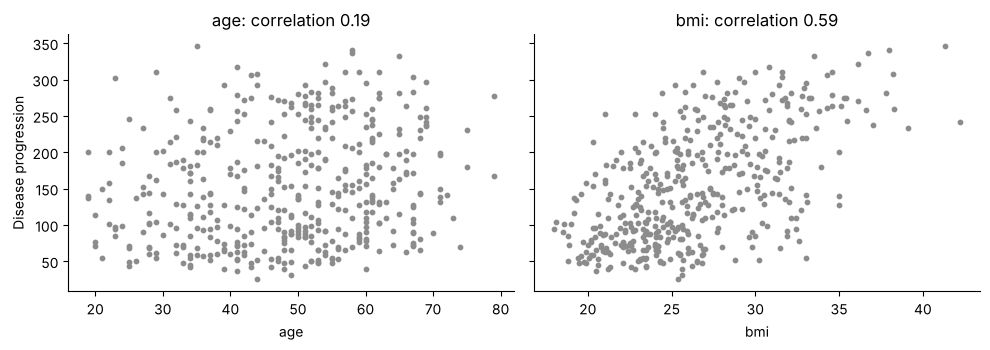

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, col in zip(axes, ["age", "bmi"]):
    r = original[col].corr(original["target"])
    ax.scatter(original[col], original["target"], s=10, color=GRAY)
    ax.set_title(f"{col}: correlation {r:.2f}")
    ax.set_xlabel(col)
axes[0].set_ylabel("Disease progression")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `for ax, col in zip(axes, ["age", "bmi"]):`: `zip(A, B)` **ghép cặp** từng phần tử của hai danh sách: ô đầu với `"age"`, ô sau với `"bmi"`. Mỗi vòng lặp nhận một cặp (ô vẽ, tên cột).
- `r = original[col].corr(original["target"])`: `.corr(...)` tính **hệ số tương quan** giữa hai cột, trả về một số từ -1 đến 1.
- `ax.scatter(original[col], original["target"], s=10, color=GRAY)`: (đã học ở A2) vẽ điểm lên ô hiện tại.
- `ax.set_title(f"{col}: correlation {r:.2f}")`: tiêu đề ô gồm tên cột và hệ số tương quan, làm tròn 2 chữ số.
- `ax.set_xlabel(col); axes[0].set_ylabel(...); plt.tight_layout(); plt.show()`: ghi nhãn và hiện hình như trước.

**Cách đọc**

- **Con số:** tuổi với điểm tiến triển có tương quan khoảng **0,19**, còn BMI khoảng **0,59**.
- **Bức tranh:** ở ô trái (tuổi), các chấm trông như đám mưa rào: người 30 tuổi có điểm từ rất thấp đến rất cao, người 70 tuổi cũng vậy. Có một xu hướng nhẹ dốc lên, nhưng đám mây dày và gần như nằm ngang. Ở ô phải (BMI) đám mây rõ ràng dốc lên: BMI cao đi cùng điểm cao.
- **Đối chiếu với lời trưởng khoa:** tuổi có liên quan, nhưng *yếu*. Biết tuổi của một người gần như không giúp đoán được điểm của họ.

Chị Hạnh muốn biết **hậu quả** bằng con số quyết định. Hãy giả sử chị chọn 20 người theo từng tiêu chí và xem trung bình điểm tiến triển *thật* của nhóm đó:

In [5]:
for col in ["age", "bmi", "s5", "bp"]:
    chosen = original.nlargest(20, col)["target"].mean()
    print(f"Top 20 by {col:4s}: average score {chosen:.0f}")
print(f"Pick at random   : average score {original['target'].mean():.0f}")
print(f"Perfect pick     : average score {original['target'].nlargest(20).mean():.0f}")

Top 20 by age : average score 187
Top 20 by bmi : average score 262
Top 20 by s5  : average score 209
Top 20 by bp  : average score 223
Pick at random   : average score 152
Perfect pick     : average score 311


**Giải thích từng dòng**

- `for col in ["age", "bmi", "s5", "bp"]:`: thử bốn tiêu chí xếp hạng.
- `chosen = original.nlargest(20, col)["target"].mean()`: `original.nlargest(20, col)` lấy **20 dòng có giá trị cột `col` lớn nhất** (lần này gọi trên cả bảng, có thêm tên cột; ở A2 ta gọi trên một cột đơn). Rồi lấy cột `target` của 20 người đó và tính trung bình: điểm tiến triển **thật** của nhóm được chọn.
- `print(f"Top 20 by {col:4s}: ...")`: in kết quả; `:4s` căn tên cột rộng 4 ký tự cho thẳng hàng.
- `original['target'].mean()`: mốc: chọn ngẫu nhiên thì trung bình cả nhóm chính là trung bình toàn sổ. (Dùng nháy đơn bên trong vì câu in đã dùng nháy kép.)
- `original['target'].nlargest(20).mean()`: trần lý thuyết: 20 người nặng nhất thật sự.

**Cách đọc**

- **Con số:** chọn theo tuổi cho nhóm có điểm trung bình khoảng 187, chỉ nhỉnh hơn chọn ngẫu nhiên (152). Chọn theo BMI cho khoảng 262, theo `bp` khoảng 223, theo `s5` khoảng 209. Mức trần là khoảng 311.
- **Bức tranh:** lời trưởng khoa không hẳn sai, nhưng nếu chị Hạnh làm theo, 20 suất của chị chỉ tốt hơn bốc thăm một chút. Chọn theo BMI mang lại nhóm nặng hơn nhiều, với **cùng số suất** và **không cần máy học nào cả**, chỉ nhờ nhìn đúng biểu đồ.
- **Điều quan trọng:** một biểu đồ và một phép tính đơn giản đã thay đổi quyết định. Đó là sức mạnh của việc nhìn dữ liệu trước khi dựng mô hình.

**Mang về chặng 2:** scatter cho thấy hai cột đi cùng nhau thế nào; hệ số tương quan tóm gọn bằng một số từ -1 đến 1. Luôn quy kết quả về quyết định: chọn theo cột nào thì nhóm được chọn nặng đến đâu.

## Chặng 3: Bản đồ tương quan, ai đi cùng ai?

**Câu hỏi:** thay vì so từng cặp, làm sao nhìn **mọi cặp cột cùng lúc**?

Ta xếp hệ số tương quan của mọi cặp cột vào một bảng vuông gọi là **ma trận tương quan**, rồi tô đậm nhạt theo độ mạnh: đậm là đi cùng nhau mạnh.

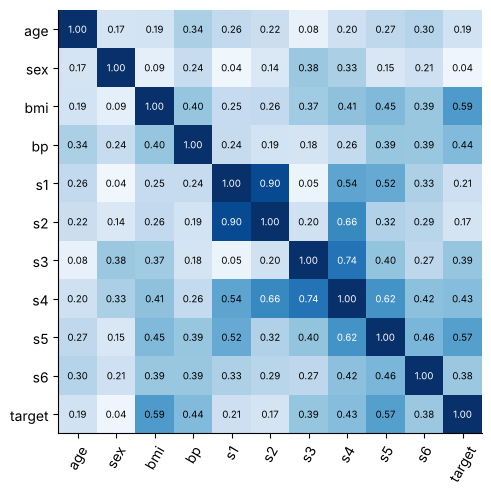

In [6]:
corr = original.corr().abs()
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if corr.iloc[i, j] > 0.6 else "black")
plt.show()

**Giải thích từng dòng**

- `corr = original.corr().abs()`: gọi `.corr()` trên **cả bảng** thì ra bảng vuông hệ số tương quan của từng cặp cột. `.abs()` bỏ dấu, vì lúc này ta chỉ quan tâm *mạnh hay yếu*, chưa quan tâm cùng chiều hay ngược chiều.
- `fig, ax = plt.subplots(figsize=(7, 5.5))`: một khung hình, một ô vẽ.
- `ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)`: (đã học `imshow` ở A2) vẽ bảng thành các ô màu. `cmap="Blues"` chọn thang màu xanh từ nhạt đến đậm. `vmin=0, vmax=1` cố định thang từ 0 đến 1 để đậm nhạt có nghĩa.
- `ax.set_xticks(range(len(corr)), corr.columns, rotation=60)`: gắn tên cột lên trục ngang (cách gọi trên ô `ax`).
- `ax.set_yticks(range(len(corr)), corr.columns)`: gắn tên cột lên trục dọc.
- `for i in range(len(corr)): for j in range(len(corr)):`: **hai vòng lặp lồng nhau** duyệt mọi ô: `i` là dòng, `j` là cột.
- `ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=...)`: `ax.text(x, y, chữ)` **viết chữ lên hình** tại vị trí (cột `j`, dòng `i`). `corr.iloc[i, j]` lấy số ở dòng `i` cột `j`. `ha` và `va` căn giữa theo chiều ngang và dọc. Phần `color="white" if ... else "black"` là cách viết gọn "nếu điều kiện đúng thì lấy giá trị này, không thì lấy giá trị kia": chữ trắng trên ô đậm (số lớn hơn 0,6), chữ đen trên ô nhạt, để luôn đọc được.

**Cách đọc**

- **Con số:** nhìn hàng (hoặc cột) `target`: `bmi` khoảng 0,59, `s5` khoảng 0,57, `bp` khoảng 0,44, `s4` khoảng 0,43, còn `age` chỉ 0,19 và `sex` gần như 0,04.
- **Bức tranh:** đường chéo luôn là 1 (một cột tương quan hoàn hảo với chính nó). Những ô đậm bên ngoài đường chéo cho biết hai *cột đề bài* đi cùng nhau. Ví dụ `s1` và `s2` tương quan **0,90**: gần như hai chứng nhân kể cùng một chuyện. Cho máy nhìn cả hai không thêm bao nhiêu thông tin mới, mà còn có thể làm nó rối (hiện tượng **đa cộng tuyến**, buổi B3).
- **Một giới hạn quan trọng:** hệ số tương quan chỉ đo mức đi cùng nhau theo **đường thẳng**. Hai cột có thể gắn bó rất chặt theo đường cong mà hệ số vẫn gần 0. Vì thế luôn nhìn scatter, không tin con số một mình.
- **Một giới hạn nữa:** đi cùng nhau chưa phải là *gây ra* nhau. BMI cao đi cùng điểm cao, nhưng ta không thể kết luận giảm BMI sẽ giảm điểm. Máy học dự đoán, không chứng minh nguyên nhân.

**Mang về chặng 3:** ma trận tương quan cho bản đồ mọi cặp cột. Hàng `target` cho biết cột nào đáng chú ý, và các ô đậm giữa hai cột đề bài cảnh báo hai cột lặp thông tin.

## Chặng 4: Biểu đồ cũng có thể nói dối

**Câu hỏi:** một người khác trong khoa đưa biểu đồ "nữ bệnh nặng hơn nam rõ rệt". Ta có nên tin?

Hãy xem cùng một dữ liệu, vẽ theo hai cách.

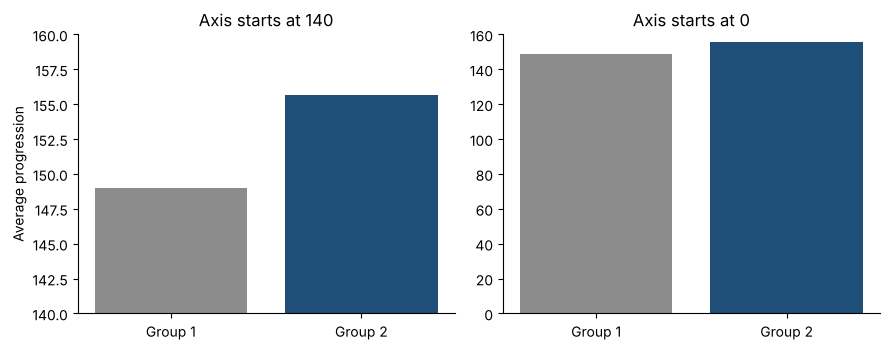

In [7]:
means = original.groupby("sex")["target"].mean()
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, low in zip(axes, [140, 0]):
    ax.bar(["Group 1", "Group 2"], means.values, color=[GRAY, BLUE])
    ax.set_ylim(low, 160)
    ax.set_title("Axis starts at " + str(low))
axes[0].set_ylabel("Average progression")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `means = original.groupby("sex")["target"].mean()`: `groupby("sex")` **gom các dòng theo nhóm** của cột `sex` (hai nhóm: 1 và 2); chọn cột `target`, rồi `.mean()` tính trung bình **riêng cho từng nhóm**. Kết quả là một dãy hai số.
- `for ax, low in zip(axes, [140, 0]):`: hai ô, hai kiểu trục: một ô bắt đầu từ 140, một ô bắt đầu từ 0.
- `ax.bar(["Group 1", "Group 2"], means.values, color=[GRAY, BLUE])`: vẽ hai cột cho hai nhóm.
- `ax.set_ylim(low, 160)`: `set_ylim` đặt **khoảng hiển thị** của trục dọc, từ `low` đến 160. Đây chính là chỗ biểu đồ có thể "nói dối".
- `ax.set_title("Axis starts at " + str(low))`: tiêu đề ghi rõ trục bắt đầu từ đâu. `str(...)` đổi số thành chữ để nối vào câu.

**Cách đọc**

- **Con số:** điểm trung bình của hai nhóm chỉ là khoảng **149** và **156**, chênh khoảng 7 điểm.
- **Bức tranh:** ô trái cắt trục từ 140 nên cột nhóm 2 cao gần gấp **đôi** cột nhóm 1: trông như một cách biệt khổng lồ. Ô phải để trục từ 0 thì hai cột gần như bằng nhau. Cả hai ô dùng đúng cùng số liệu. Trục bị cắt làm cho một chênh lệch bé trông to.
- **Biểu đồ nên dùng:** nếu muốn so sánh hai nhóm công bằng, hãy cho thấy cả **độ phân tán**, không chỉ trung bình. Biểu đồ hộp (boxplot) làm đúng việc này.

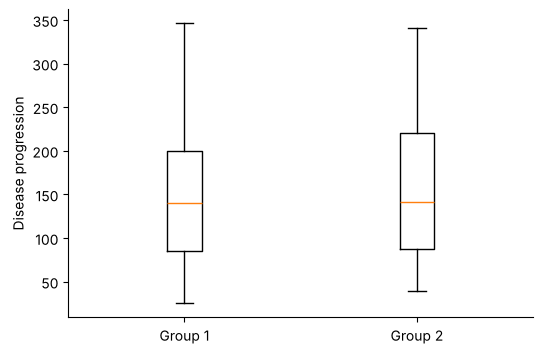

In [8]:
groups = [original.loc[original["sex"] == s, "target"] for s in [1, 2]]
plt.boxplot(groups, tick_labels=["Group 1", "Group 2"])
plt.ylabel("Disease progression")
plt.show()

**Giải thích từng dòng**

- `groups = [original.loc[original["sex"] == s, "target"] for s in [1, 2]]`: tạo danh sách hai dãy điểm: với mỗi nhóm `s`, lọc những dòng có `sex` bằng `s` (dấu `==` nghĩa là "bằng", khác dấu `=` là gán) rồi lấy cột `target`.
- `plt.boxplot(groups, tick_labels=["Group 1", "Group 2"])`: `plt.boxplot` vẽ **biểu đồ hộp**: mỗi nhóm một hộp. Phần hộp chứa 50% số người ở giữa (từ phân vị 25% đến 75%), vạch ngang trong hộp là **trung vị**, hai râu kéo ra tới những giá trị bình thường xa nhất, và các chấm lẻ ngoài râu là ca **bất thường**. `tick_labels` đặt tên cho từng hộp.

**Cách đọc**

- **Con số:** hai hộp gần như nằm chồng lên nhau, trung vị gần bằng nhau (khoảng 140).
- **Bức tranh:** trong **cùng một nhóm**, điểm trải từ vài chục đến hơn 300. Độ trải *trong nhóm* lớn hơn nhiều so với chênh lệch *giữa hai nhóm*. Biết một người thuộc nhóm nào gần như không giúp đoán được điểm của họ. Đó cũng là lý do hệ số tương quan của `sex` chỉ 0,04.
- **Quy tắc nghề:** trước khi tin một biểu đồ, hỏi ba câu: trục bắt đầu từ đâu, có cho thấy độ phân tán không, và có phải mình đang nhìn trung bình thay cho cả đám đông không.

**Mang về chặng 4:** trục bị cắt và chỉ vẽ trung bình đều có thể làm một chênh lệch bé trông to. Biểu đồ hộp cho thấy cả độ phân tán và những ca bất thường.

## Phán quyết và bài học nghề

**Phán quyết.**

- **Con số:** tuổi chỉ tương quan 0,19 với điểm tiến triển. Nếu chị Hạnh chọn 20 người cao tuổi nhất, nhóm có điểm trung bình khoảng 187; chọn 20 người BMI cao nhất, nhóm khoảng 262, gần với mức trần 311 hơn nhiều.
- **Khuyến nghị:** không xếp ưu tiên theo tuổi. Dùng BMI (và sau này là các cột khác, qua máy học) để xếp hạng. Chuyển câu hỏi cho máy khi một cột không đủ.
- **Việc cần làm tiếp:** các cột `s1` và `s2` lặp thông tin nhau, cần chú ý khi cho máy nhìn nhiều cột.

**Bài học nghề.**

1. **Nhìn trước, tính sau.** Histogram và scatter bắt được cái bảng số che mất.
2. **Một con số tóm tắt luôn mất thông tin.** Trung bình che đuôi dài, hệ số tương quan che đường cong.
3. **Đừng tin biểu đồ khi chưa kiểm tra trục.** Trục cắt cụt là chiêu cũ nhất.
4. **Tương quan không phải nhân quả.** Dữ liệu này cho phép *dự đoán*, không cho phép *kết luận nguyên nhân*.

**Một điều thành thật:** mọi con số tương quan ở đây tính trên cả 442 người, kể cả những người ta sẽ dùng để đánh giá về sau. Với việc *khám phá* thì chấp nhận được, nhưng khi *đánh giá mô hình* ta phải chia sổ thành tập học và tập thi (buổi A4).

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Histogram cho thấy hình dạng của đám đông. Trung bình không kể hết câu chuyện. |
| 1 | `df.hist()` cho chân dung mọi cột chỉ bằng một dòng, trước khi so sánh cột nào với cột nào. |
| 2 | Scatter và hệ số tương quan cho biết hai cột đi cùng nhau thế nào. Quy mọi thứ về quyết định cụ thể. |
| 3 | Ma trận tương quan là bản đồ mọi cặp cột; cảnh báo cặp cột lặp thông tin. Tương quan không phải nhân quả. |
| 4 | Cắt trục và chỉ vẽ trung bình có thể làm chênh lệch bé trông to. Boxplot cho thấy cả độ phân tán. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Đếm xem mỗi khoảng có bao nhiêu người | biểu đồ tần suất (histogram) | `plt.hist`, `df.hist()` |
| Mỗi người một chấm | biểu đồ phân tán (scatter) | `plt.scatter` |
| Hai cột đi cùng nhau mạnh đến đâu | hệ số tương quan (correlation) | `a.corr(b)` |
| Bản đồ nhiệt của mọi cặp cột | ma trận tương quan | `df.corr()`, `imshow` |
| Gom người theo nhóm rồi tính riêng | nhóm theo (group by) | `df.groupby(...)` |
| Hộp chứa nửa số người ở giữa | biểu đồ hộp (boxplot) | `plt.boxplot` |
| Chọn ra những người cao nhất theo một cột | lấy k dòng lớn nhất | `df.nlargest(k, col)` |
| Hai cột kể cùng một chuyện | đa cộng tuyến (multicollinearity) | `s1` và `s2`, tương quan 0,90 |

**Thử thách tự làm**

1. Vẽ histogram riêng của `bmi` cho hai nhóm `sex` (hai ô cạnh nhau). Hai nhóm có phân bố BMI giống nhau không? (Gợi ý: dùng `original.loc[original["sex"] == 1, "bmi"]` như ở chặng 4.)
2. Thử thêm cột `s4` và `s3` vào vòng lặp chọn top 20 ở chặng 2. Cột nào cho nhóm nặng nhất? Có cột nào cho nhóm nhẹ hơn chọn ngẫu nhiên không? (Gợi ý: `s3` tương quan **âm** với điểm, nên dùng `nsmallest` thay `nlargest`.)
3. Đổi `bins=20` thành 5 rồi thành 100 ở chặng 0. Hình dạng đám đông thay đổi thế nào, và số bins nào kể câu chuyện rõ nhất? (Gợi ý: quá ít thì mất chi tiết, quá nhiều thì lởm chởm.)

**Checklist năng lực** (tự tick khi làm được)

- [ ] Đọc được một histogram: hình dạng, độ lệch, ca bất thường.
- [ ] Đọc được scatter và hệ số tương quan, biết hệ số gần 0 hay gần ±1 nghĩa là gì.
- [ ] Đọc được ma trận tương quan và nhận ra cặp cột lặp thông tin.
- [ ] Nhận ra một biểu đồ bị cắt trục hay chỉ vẽ trung bình.
- [ ] Quy một phát hiện từ biểu đồ về một quyết định cụ thể.

## Phần thưởng (Tip pro): Khi tương quan gần 0 mà hai cột vẫn gắn bó chặt


Hệ số tương quan chỉ bắt được mối liên hệ theo **đường thẳng**. Nếu hai cột gắn với nhau theo đường cong chữ U, hệ số có thể gần 0 dù cột này quyết định gần như hoàn toàn cột kia. Chạy ô dưới để thấy: `x` đi từ -3 đến 3, `y = x²`.

Correlation between x and x squared: -0.0


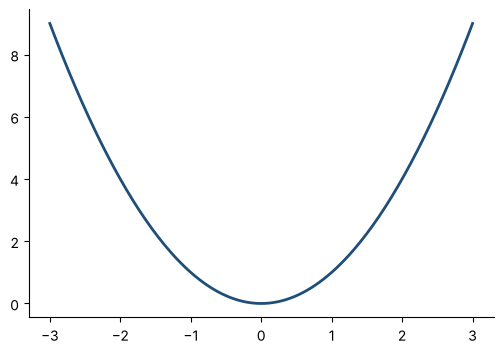

In [9]:
x = np.linspace(-3, 3, 200)
y_curve = x ** 2
print("Correlation between x and x squared:", round(np.corrcoef(x, y_curve)[0, 1], 3))
plt.plot(x, y_curve, color=BLUE, linewidth=2)
plt.show()

**Giải thích từng dòng**

- `x = np.linspace(-3, 3, 200)`: (đã học ở A1) 200 số cách đều từ -3 đến 3.
- `y_curve = x ** 2`: `**` là **lũy thừa**: `x ** 2` là x bình phương. Cả dãy `x` được bình phương cùng lúc.
- `print("Correlation ...", round(np.corrcoef(x, y_curve)[0, 1], 3))`: `np.corrcoef` tính ma trận tương quan của hai dãy số, `[0, 1]` lấy số tương quan giữa dãy đầu và dãy sau. Kết quả gần **0**, dù `y_curve` được quyết định hoàn toàn bởi `x`.
- `plt.plot(x, y_curve, color=BLUE, linewidth=2)`: vẽ đường cong chữ U cho thấy mối liên hệ chặt chẽ mà hệ số tương quan không thấy.